# Fases Analyze y Share
Usa las tablas limpias de `../data/clean/` producidas por `01_prepare_process.ipynb`. Responde P1 a P4 y genera las gráficas finales en `../figuras/`.
Las decisiones de análisis tienen identificador `A-xx` (ver `../docs/bitacora_decisiones.md`).
**Recordatorio metodológico:** todos los resultados son asociaciones en el tiempo; ninguno prueba causalidad.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
BASE = Path('..').resolve(); CLEAN = BASE/'data'/'clean'; FIG = BASE/'figuras'; OUT = BASE/'data'/'resultados'
OUT.mkdir(exist_ok=True)
q   = pd.read_csv(CLEAN/'nvda_ingresos_trimestrales.csv', parse_dates=['fin'])
an  = pd.read_csv(CLEAN/'nvda_ingresos_anuales.csv')
px  = pd.read_csv(CLEAN/'precios_diarios_eeuu.csv', parse_dates=['fecha']).set_index('fecha')
ev  = pd.read_csv(CLEAN/'eventos_controles_exportacion.csv', parse_dates=['fecha_reaccion'])
riv = pd.read_csv(CLEAN/'rivales_china_ingresos_anuales.csv')
asml= pd.read_csv(CLEAN/'asml_ingresos_china_anual.csv')
sia = pd.read_csv(CLEAN/'semiconductores_ventas_globales_sia.csv')
pxcn= pd.read_csv(CLEAN/'precios_diarios_rivales_china.csv', parse_dates=['fecha']).set_index('fecha')

# Estilo de gráficas (paleta categórica validada; texto en tinta neutra)
S1, S2, S3, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
TXT, TXT2 = '#0b0b0b', '#52514e'
mpl.rcParams.update({'font.size': 10, 'axes.edgecolor': '#c9c8c3', 'axes.labelcolor': TXT2, 'xtick.color': TXT2,
                     'ytick.color': TXT2, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': TXT,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#ecebe7',
                     'grid.linewidth': 0.8, 'axes.axisbelow': True, 'legend.frameon': False, 'lines.linewidth': 2,
                     'figure.facecolor': 'white', 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
def nota(fig, txt, y=-0.02): fig.text(0.01, y, txt, fontsize=8, color=TXT2, ha='left', va='top', wrap=True)

## P1. ¿Cuánto cambió el peso de China después de cada ronda de controles?
**A-01** Se definen cuatro "regímenes" regulatorios según el trimestre fiscal en que entró en vigor cada regla:
- R0 Sin controles: FY2020-T3 a FY2023-T2 (hasta jul-2022).
- R1 Controles 2022 (A100/H100 requieren licencia; Nvidia vende A800/H800): FY2023-T3 a FY2024-T3.
- R2 Controles oct-2023 (A800/H800 restringidos; Nvidia vende H20): FY2024-T4 a FY2026-T1.
- R3 H20 requiere licencia (abr-2025) y H200 sólo con licencia y bloqueo chino: FY2026-T2 en adelante.

Se compara el promedio del peso de China en cada régimen **dentro de cada base** (D-05).

In [2]:
def regimen(p):
    fy, t = int(p[2:6]), int(p[-1]); k = fy*10 + t
    if k <= 20232: return 'R0 Sin controles'
    if k <= 20243: return 'R1 Controles 2022'
    if k <= 20261: return 'R2 Controles oct-2023'
    return 'R3 Licencia H20 / H200'
q['regimen'] = q.periodo.map(regimen)
p1 = (q.groupby(['base', 'regimen'])
       .agg(trimestres=('periodo', 'count'), desde=('periodo', 'first'), hasta=('periodo', 'last'),
            china_prom_musd=('china', 'mean'), total_prom_musd=('total', 'mean'), pct_china_prom=('pct_china', 'mean'),
            pct_china_min=('pct_china', 'min'), pct_china_max=('pct_china', 'max'))
       .round(1).reset_index())
p1.to_csv(OUT/'p1_regimenes.csv', index=False); p1

,base,regimen,trimestres,desde,hasta,china_prom_musd,total_prom_musd,pct_china_prom,pct_china_min,pct_china_max
0,facturacion,R0 Sin controles,12,FY2020-Q3,FY2023-Q2,1356.2,5391.7,25.0,22.1,28.4
1,facturacion,R1 Controles 2022,5,FY2023-Q3,FY2024-Q3,2092.4,10160.2,20.0,15.8,22.2
2,facturacion,R2 Controles oct-2023,6,FY2024-Q4,FY2026-Q1,4096.0,32777.0,12.1,8.8,15.4
3,facturacion,R3 Licencia H20 / H200,1,FY2026-Q2,FY2026-Q2,2769.0,46743.0,5.9,5.9,5.9
4,sede_cliente,R2 Controles oct-2023,3,FY2025-Q3,FY2026-Q1,8539.7,39491.7,21.7,19.9,23.2
5,sede_cliente,R3 Licencia H20 / H200,5,FY2026-Q2,FY2027-Q2,4489.6,69942.4,6.4,4.5,8.5


In [3]:
# Cambio interanual de los ingresos de China (mismo trimestre del año anterior, misma base)
q = q.sort_values(['base', 'fin'])
q['china_yoy_pct'] = q.groupby('base').china.pct_change(4) * 100
q['total_yoy_pct'] = q.groupby('base').total.pct_change(4) * 100
q[q.base == 'sede_cliente'][['periodo', 'china', 'pct_china', 'china_yoy_pct', 'total_yoy_pct']].round(1)

,periodo,china,pct_china,china_yoy_pct,total_yoy_pct
24,FY2025-Q3,8142.0,23.2,NaN,NaN
25,FY2025-Q4,7818.0,19.9,NaN,NaN
26,FY2026-Q1,9659.0,21.9,NaN,NaN
27,FY2026-Q2,3985.0,8.5,NaN,NaN
28,FY2026-Q3,2973.0,5.2,-63.5,62.5
29,FY2026-Q4,3060.0,4.5,-60.9,73.2
30,FY2027-Q1,4550.0,5.6,-52.9,85.2
31,FY2027-Q2,7880.0,8.2,97.7,105.9


## P2. ¿Cómo reaccionó la acción en los días de anuncio? (estudio de eventos)
**A-02** Modelo de mercado: $r_{NVDA,t} = \alpha + \beta\, r_{M,t} + \varepsilon_t$, estimado en la ventana [-250, -11] días hábiles antes del evento.
Rendimiento anormal $AR_t = r_{NVDA,t} - (\hat\alpha + \hat\beta r_{M,t})$; se acumula en la ventana (-1, +1) → CAR.
Prueba t: $t = CAR / (\hat\sigma_\varepsilon \sqrt{3})$. **A-03** Dos referencias: S&P 500 (mercado) y SOX (sector). Ojo: Nvidia pesa mucho dentro del SOX, así que contra SOX el efecto tiende a verse más pequeño.
**A-04** Con 12 eventos la muestra es pequeña; los resultados son indicativos. Varios eventos coinciden con otras noticias (por ejemplo, abril de 2025 con la guerra arancelaria), así que la reacción no se atribuye sólo al control.

In [4]:
def car(evento, mkt, est=(-250, -11), win=(-1, 1)):
    fechas = px.index; i0 = fechas.get_indexer([evento])[0]
    e = px.iloc[i0+est[0]:i0+est[1]+1]; w = px.iloc[i0+win[0]:i0+win[1]+1]
    b, a = np.polyfit(e[f'r_{mkt}'], e['r_NVDA'], 1)
    sigma = (e['r_NVDA'] - (a + b*e[f'r_{mkt}'])).std(ddof=2)
    ar = w['r_NVDA'] - (a + b*w[f'r_{mkt}'])
    n = len(w); c = ar.sum()
    return pd.Series({f'beta_{mkt}': b, f'CAR_{mkt}_pct': 100*(np.exp(c)-1), f't_{mkt}': c/(sigma*np.sqrt(n))})

filas = []
for _, r in ev.iterrows():
    s = pd.concat([car(r.fecha_reaccion, 'SP500'), car(r.fecha_reaccion, 'SOX')])
    s['rend_NVDA_dia0_pct'] = 100*(np.exp(px.loc[r.fecha_reaccion, 'r_NVDA'])-1)
    filas.append(pd.concat([r[['id', 'fecha_reaccion', 'origen', 'descripcion']], s]))
p2 = pd.DataFrame(filas)
p2['signif_5pct_SP500'] = p2.t_SP500.abs() > 1.96
p2.round({c: 2 for c in p2.select_dtypes('number').columns}).to_csv(OUT/'p2_estudio_eventos.csv', index=False)
p2[['id', 'fecha_reaccion', 'origen', 'rend_NVDA_dia0_pct', 'CAR_SP500_pct', 't_SP500', 'CAR_SOX_pct', 't_SOX']].round({'rend_NVDA_dia0_pct': 2, 'CAR_SP500_pct': 2, 't_SP500': 2, 'CAR_SOX_pct': 2, 't_SOX': 2})

,id,fecha_reaccion,origen,rend_NVDA_dia0_pct,CAR_SP500_pct,t_SP500,CAR_SOX_pct,t_SOX
0,E1,2022-09-01,EE.UU.,-7.67,-8.44,-2.26,-6.48,-2.52
1,E2,2022-10-07,EE.UU.,-8.03,-1.50,-0.37,2.50,0.91
2,E3,2023-10-17,EE.UU.,-4.68,-7.73,-1.85,-6.63,-2.11
3,E4,2024-12-09,China,-2.55,-5.65,-1.36,-4.92,-1.45
4,E5,2025-01-13,EE.UU.,-1.97,-3.09,-0.71,-4.26,-1.21
5,E6,2025-04-16,EE.UU.,-6.87,-2.26,-0.49,-3.68,-1.02
6,E7,2025-07-15,EE.UU.,4.04,3.77,0.86,3.60,1.04
7,E8,2025-08-11,EE.UU.,-0.35,-2.19,-0.55,-2.90,-0.90
8,E9,2025-09-17,China,-2.62,-1.49,-0.39,-4.73,-1.53
9,E10,2025-12-08,EE.UU.,1.72,1.24,0.33,-1.29,-0.41


In [5]:
# Promedio por tipo de evento (restricción vs. apertura) y por origen
ev_tipo = {'E1': 'Restricción', 'E2': 'Restricción', 'E3': 'Restricción', 'E4': 'Restricción', 'E5': 'Restricción',
           'E6': 'Restricción', 'E7': 'Apertura', 'E8': 'Apertura', 'E9': 'Restricción', 'E10': 'Apertura',
           'E11': 'Restricción', 'E12': 'Apertura'}   # A-05
p2['tipo'] = p2.id.map(ev_tipo)
resumen_p2 = p2.groupby(['tipo']).agg(eventos=('id', 'count'), CAR_SP500_prom=('CAR_SP500_pct', 'mean'),
                                      CAR_SOX_prom=('CAR_SOX_pct', 'mean'), signif=('signif_5pct_SP500', 'sum')).round(2)
resumen_p2.to_csv(OUT/'p2_resumen_por_tipo.csv'); resumen_p2

,eventos,CAR_SP500_prom,CAR_SOX_prom,signif
tipo,,,,
Apertura,4,0.48,-0.14,0
Restricción,8,-3.52,-3.65,1


## P3. ¿El crecimiento en otras regiones y en Data Center compensó la pérdida de China?
**A-06** Descomposición del cambio anual de ingresos por región, dentro de cada base: facturación FY2022→FY2025 y sede del cliente FY2025→FY2026 (el año en que China cayó en términos absolutos).

In [6]:
def descomp(b, y0, y1):
    a = an.set_index('anio_fiscal')
    reg = {'EE.UU.': f'eeuu_{b}', 'Taiwán': f'taiwan_{b}', 'China': f'china_{b}'}
    d = {k: a.loc[y1, v] - a.loc[y0, v] for k, v in reg.items()}
    d['Otros'] = (a.loc[y1, 'total'] - a.loc[y1, list(reg.values())].sum()) - (a.loc[y0, 'total'] - a.loc[y0, list(reg.values())].sum())
    out = pd.DataFrame({'region': list(d), 'cambio_musd': list(d.values())})
    out['base'] = b; out['periodo'] = f'FY{y0}→FY{y1}'; out['pct_del_cambio_total'] = 100*out.cambio_musd/out.cambio_musd.sum()
    return out
p3 = pd.concat([descomp('facturacion', 2022, 2025), descomp('sede_cliente', 2025, 2026)]).round(1)
p3.to_csv(OUT/'p3_descomposicion.csv', index=False); p3

,region,cambio_musd,base,periodo,pct_del_cambio_total
0,EE.UU.,56908.0,facturacion,FY2022→FY2025,54.9
1,Taiwán,12029.0,facturacion,FY2022→FY2025,11.6
2,China,9997.0,facturacion,FY2022→FY2025,9.7
3,Otros,24649.0,facturacion,FY2022→FY2025,23.8
0,EE.UU.,72135.0,sede_cliente,FY2025→FY2026,84.4
1,Taiwán,18745.0,sede_cliente,FY2025→FY2026,21.9
2,China,-5371.0,sede_cliente,FY2025→FY2026,-6.3
3,Otros,-68.0,sede_cliente,FY2025→FY2026,-0.1


In [7]:
# Peso de Data Center y tamaño de Nvidia frente a la industria (A-07: FY de Nvidia ≈ año calendario anterior, desfase de 1 mes)
ctx = an[['anio_fiscal', 'total', 'data_center']].copy()
ctx['pct_dc'] = 100*ctx.data_center/ctx.total
ctx['anio_calendario_aprox'] = ctx.anio_fiscal - 1
ctx = ctx.merge(sia[['anio', 'ventas_globales_musd']], left_on='anio_calendario_aprox', right_on='anio', how='left').drop(columns='anio')
ctx['pct_nvda_en_industria'] = 100*ctx.total/ctx.ventas_globales_musd
ctx.round(1).to_csv(OUT/'p3_contexto_industria.csv', index=False); ctx.round(1)

,anio_fiscal,total,data_center,pct_dc,anio_calendario_aprox,ventas_globales_musd,pct_nvda_en_industria
0,2019,11716.0,2932.0,25.0,2018,NaN,NaN
1,2020,10918.0,2983.0,27.3,2019,412100.0,2.6
2,2021,16675.0,6696.0,40.2,2020,439000.0,3.8
3,2022,26914.0,10613.0,39.4,2021,555900.0,4.8
4,2023,26974.0,15005.0,55.6,2022,574100.0,4.7
5,2024,60922.0,47525.0,78.0,2023,526800.0,11.6
6,2025,130497.0,115186.0,88.3,2024,627600.0,20.8
7,2026,215938.0,193737.0,89.7,2025,791700.0,27.3


## P4. ¿Los rivales chinos crecieron cuando se endurecieron los controles? (asociación)
**A-08** Se comparan tasas de crecimiento (no montos: distintas monedas). Con 4 años por empresa no se calcula correlación porque no sería informativa.

In [8]:
r4 = riv.pivot(index='anio', columns='empresa', values='ingresos_millones')
idx = (100*r4/r4.loc[2022]).round(0)
idx.to_csv(OUT/'p4_rivales_indice_2022.csv'); print(idx)
# Desempeño bursátil desde el primer control (31-ago-2022) al corte
def rend(s, d0='2022-08-31'):
    s = s.dropna(); return 100*(s.iloc[-1]/s[s.index >= d0].iloc[0]-1)
bolsa = pd.Series({'NVDA': rend(px.NVDA), 'S&P 500': rend(px.SP500), 'SOX': rend(px.SOX),
                   'Cambricon': rend(pxcn['688256.SS']), 'Hygon': rend(pxcn['688041.SS']), 'SMIC (Shanghái)': rend(pxcn['688981.SS'])}).round(0)
bolsa.to_csv(OUT/'p4_rend_bolsa_desde_ago2022.csv'); bolsa

empresa  Cambricon  Hygon   SMIC
anio                            
2022         100.0  100.0  100.0
2023          97.0  117.0   87.0
2024         161.0  179.0  110.0
2025         891.0  281.0  128.0


NVDA                871.0
S&P 500              81.0
SOX                 252.0
Cambricon          2258.0
Hygon               260.0
SMIC (Shanghái)     204.0
dtype: float64

## Recuadro ASML: peso de China en ventas (calendario) frente a Nvidia

In [9]:
cmp_ = asml[['anio', 'pct_china']].rename(columns={'pct_china': 'ASML'})
nv = an[['anio_fiscal', 'pct_china_facturacion', 'pct_china_sede_cliente']].copy(); nv['anio'] = nv.anio_fiscal - 1
cmp_ = cmp_.merge(nv.drop(columns='anio_fiscal'), on='anio', how='left').round(1)
cmp_.to_csv(OUT/'asml_vs_nvda.csv', index=False); cmp_

,anio,ASML,pct_china_facturacion,pct_china_sede_cliente
0,2017,10.3,NaN,NaN
1,2018,16.8,23.9,NaN
2,2019,11.7,25.0,NaN
3,2020,16.6,23.3,NaN
4,2021,14.7,26.4,NaN
5,2022,13.8,21.4,NaN
6,2023,26.3,16.9,20.2
7,2024,36.1,13.1,19.2
8,2025,29.1,NaN,9.1


## Share: gráficas finales

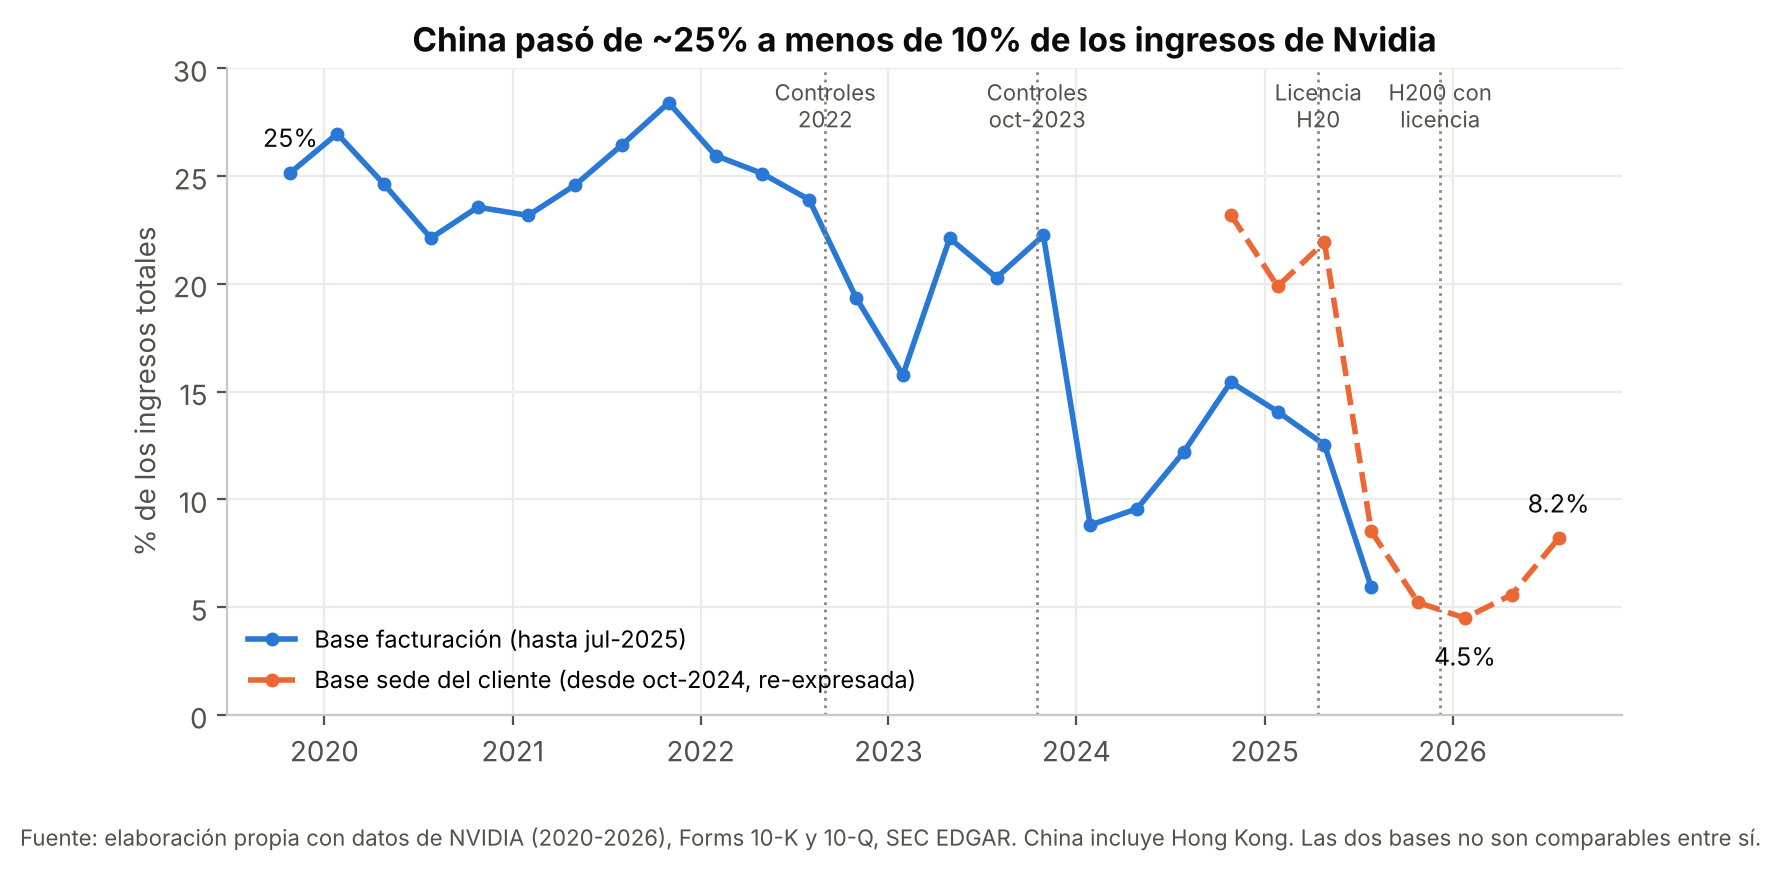

In [10]:
# Figura 1: peso de China por trimestre, con las reglas marcadas
fig, ax = plt.subplots(figsize=(9, 4.2))
f, h = q[q.base == 'facturacion'], q[q.base == 'sede_cliente']
ax.plot(f.fin, f.pct_china, color=S1, marker='o', ms=4, label='Base facturación (hasta jul-2025)')
ax.plot(h.fin, h.pct_china, color=S2, marker='o', ms=4, ls='--', label='Base sede del cliente (desde oct-2024, re-expresada)')
for d, t in [('2022-08-31', 'Controles\n2022'), ('2023-10-17', 'Controles\noct-2023'), ('2025-04-15', 'Licencia\nH20'), ('2025-12-08', 'H200 con\nlicencia')]:
    ax.axvline(pd.Timestamp(d), color=GRIS, lw=1, ls=':'); ax.text(pd.Timestamp(d), 29.5, t, fontsize=8, color=TXT2, ha='center', va='top')
ax.text(f.fin.iloc[0], f.pct_china.iloc[0]+1.2, f'{f.pct_china.iloc[0]:.0f}%', color=TXT, fontsize=9, ha='center')
ax.text(h.fin.iloc[-1], h.pct_china.iloc[-1]+1.2, f'{h.pct_china.iloc[-1]:.1f}%', color=TXT, fontsize=9, ha='center')
ax.text(h.fin.iloc[5], h.pct_china.iloc[5]-2.2, f'{h.pct_china.iloc[5]:.1f}%', color=TXT, fontsize=9, ha='center')
ax.set_ylim(0, 30); ax.set_ylabel('% de los ingresos totales')
ax.set_title('China pasó de ~25% a menos de 10% de los ingresos de Nvidia')
ax.legend(loc='lower left', fontsize=8.5)
nota(fig, 'Fuente: elaboración propia con datos de NVIDIA (2020-2026), Forms 10-K y 10-Q, SEC EDGAR. China incluye Hong Kong. Las dos bases no son comparables entre sí.')
fig.savefig(FIG/'fig1_peso_china_trimestral.png'); plt.show()

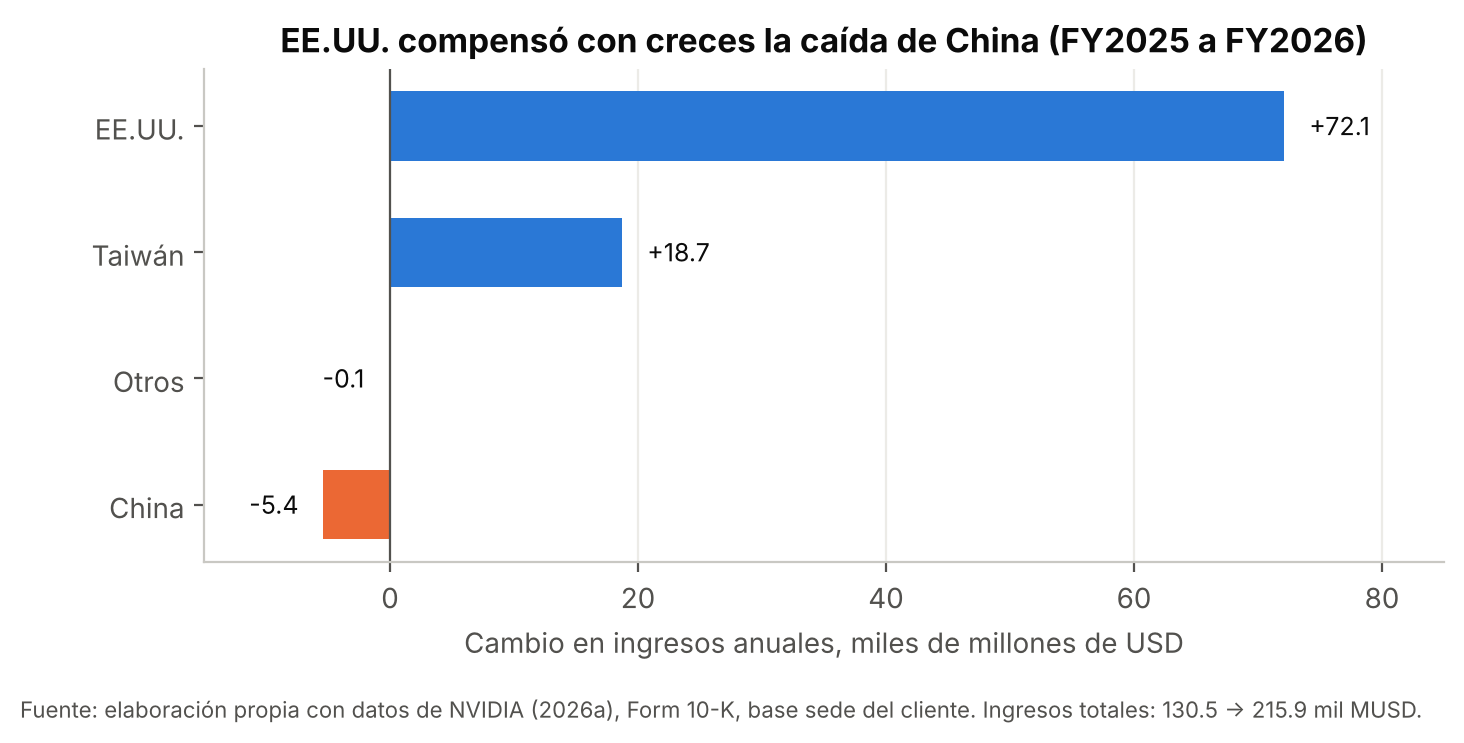

In [11]:
# Figura 2: de dónde vino el crecimiento (base sede del cliente, FY2025→FY2026)
d = p3[p3.base == 'sede_cliente'].set_index('region').cambio_musd.reindex(['EE.UU.', 'Taiwán', 'Otros', 'China'])/1000
fig, ax = plt.subplots(figsize=(8, 3.2))
cols = [S1 if v >= 0 else S2 for v in d]
ax.barh(d.index[::-1], d.values[::-1], color=cols[::-1], height=0.55)
for y, v in zip(d.index[::-1], d.values[::-1]):
    ax.text(v + (2 if v >= 0 else -2), y, f'{v:+,.1f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9, color=TXT)
ax.axvline(0, color=TXT2, lw=0.8); ax.set_xlabel('Cambio en ingresos anuales, miles de millones de USD')
ax.set_xlim(-15, 85); ax.grid(axis='y', visible=False)
ax.set_title('EE.UU. compensó con creces la caída de China (FY2025 a FY2026)')
nota(fig, 'Fuente: elaboración propia con datos de NVIDIA (2026a), Form 10-K, base sede del cliente. Ingresos totales: 130.5 → 215.9 mil MUSD.', y=-0.1)
fig.savefig(FIG/'fig2_descomposicion_regiones.png'); plt.show()

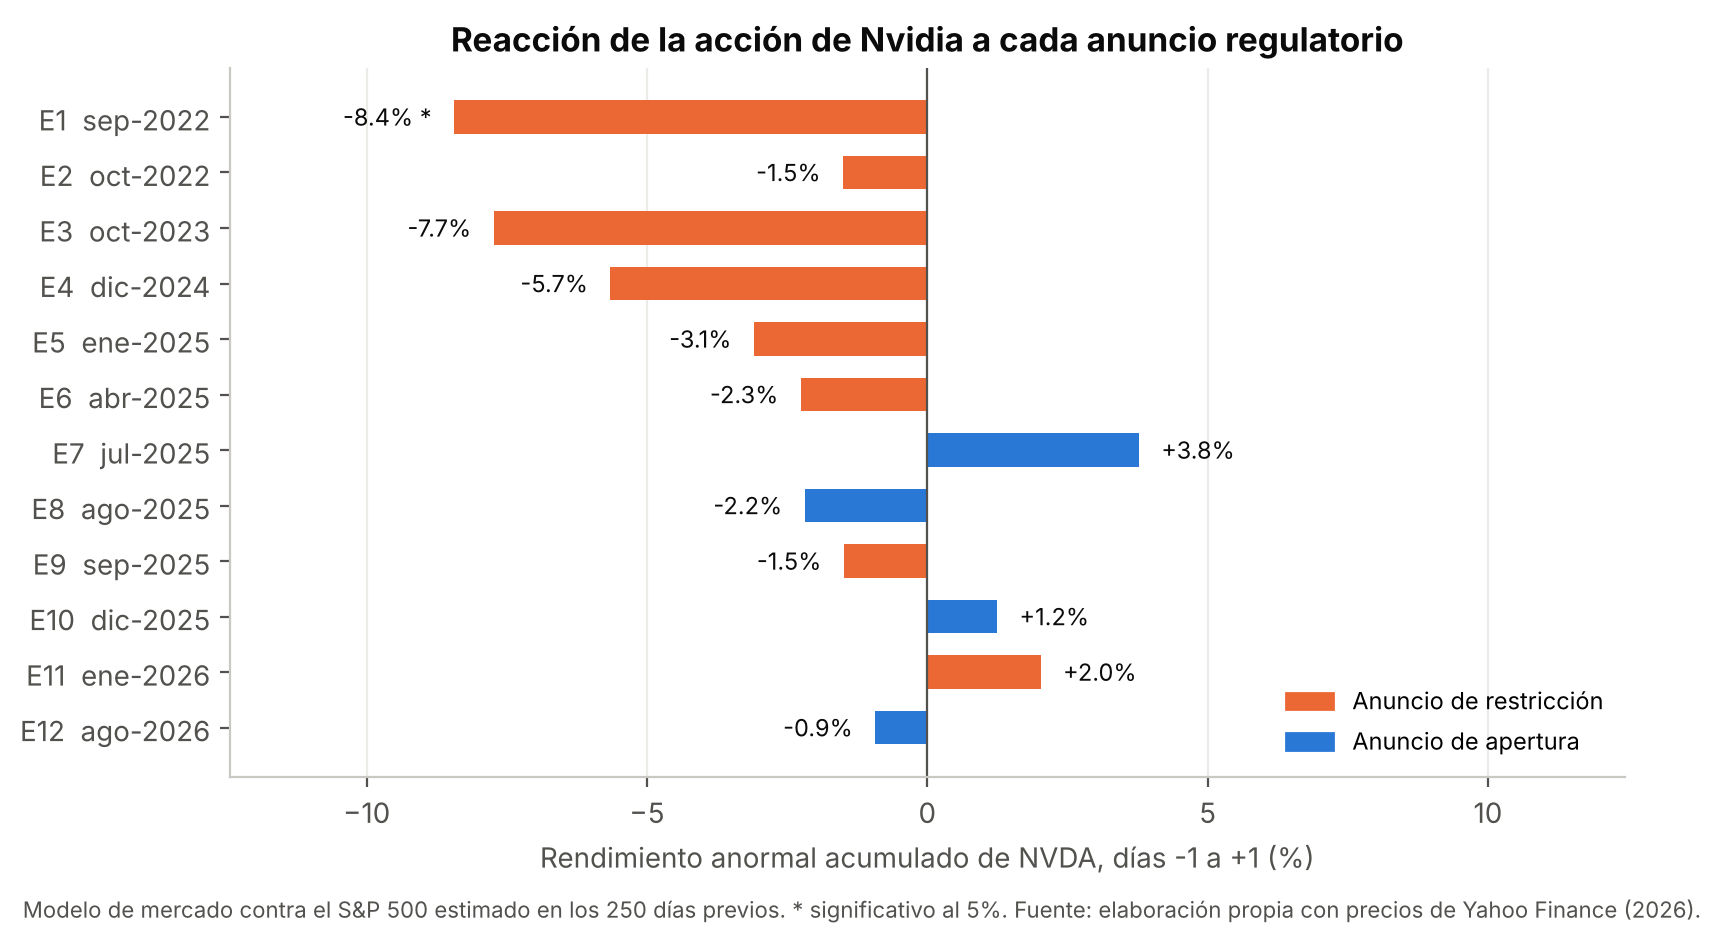

In [12]:
# Figura 3: reacción de la acción (CAR -1,+1 contra S&P 500) por evento
d = p2.sort_values('fecha_reaccion')
MES = dict(enumerate(["ene","feb","mar","abr","may","jun","jul","ago","sep","oct","nov","dic"], 1))
etiquetas = [f"{i}  {MES[fch.month]}-{fch.year}" for i, fch in zip(d.id, d.fecha_reaccion)]
fig, ax = plt.subplots(figsize=(9, 4.6))
cols = [S2 if t == 'Restricción' else S1 for t in d.tipo]
ax.barh(etiquetas[::-1], d.CAR_SP500_pct.values[::-1], color=cols[::-1], height=0.6)
for y, v, s in zip(etiquetas[::-1], d.CAR_SP500_pct.values[::-1], d.signif_5pct_SP500.values[::-1]):
    ax.text(v + (0.4 if v >= 0 else -0.4), y, f'{v:+.1f}%' + (' *' if s else ''), va='center', ha='left' if v >= 0 else 'right', fontsize=8.5, color=TXT)
ax.axvline(0, color=TXT2, lw=0.8); ax.grid(axis='y', visible=False)
lim = max(abs(d.CAR_SP500_pct).max()+4, 10); ax.set_xlim(-lim, lim)
ax.set_xlabel('Rendimiento anormal acumulado de NVDA, días -1 a +1 (%)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=S2, label='Anuncio de restricción'), Patch(color=S1, label='Anuncio de apertura')], loc='lower right', fontsize=8.5)
ax.set_title('Reacción de la acción de Nvidia a cada anuncio regulatorio')
nota(fig, 'Modelo de mercado contra el S&P 500 estimado en los 250 días previos. * significativo al 5%. Fuente: elaboración propia con precios de Yahoo Finance (2026).')
fig.savefig(FIG/'fig3_estudio_eventos.png'); plt.show()

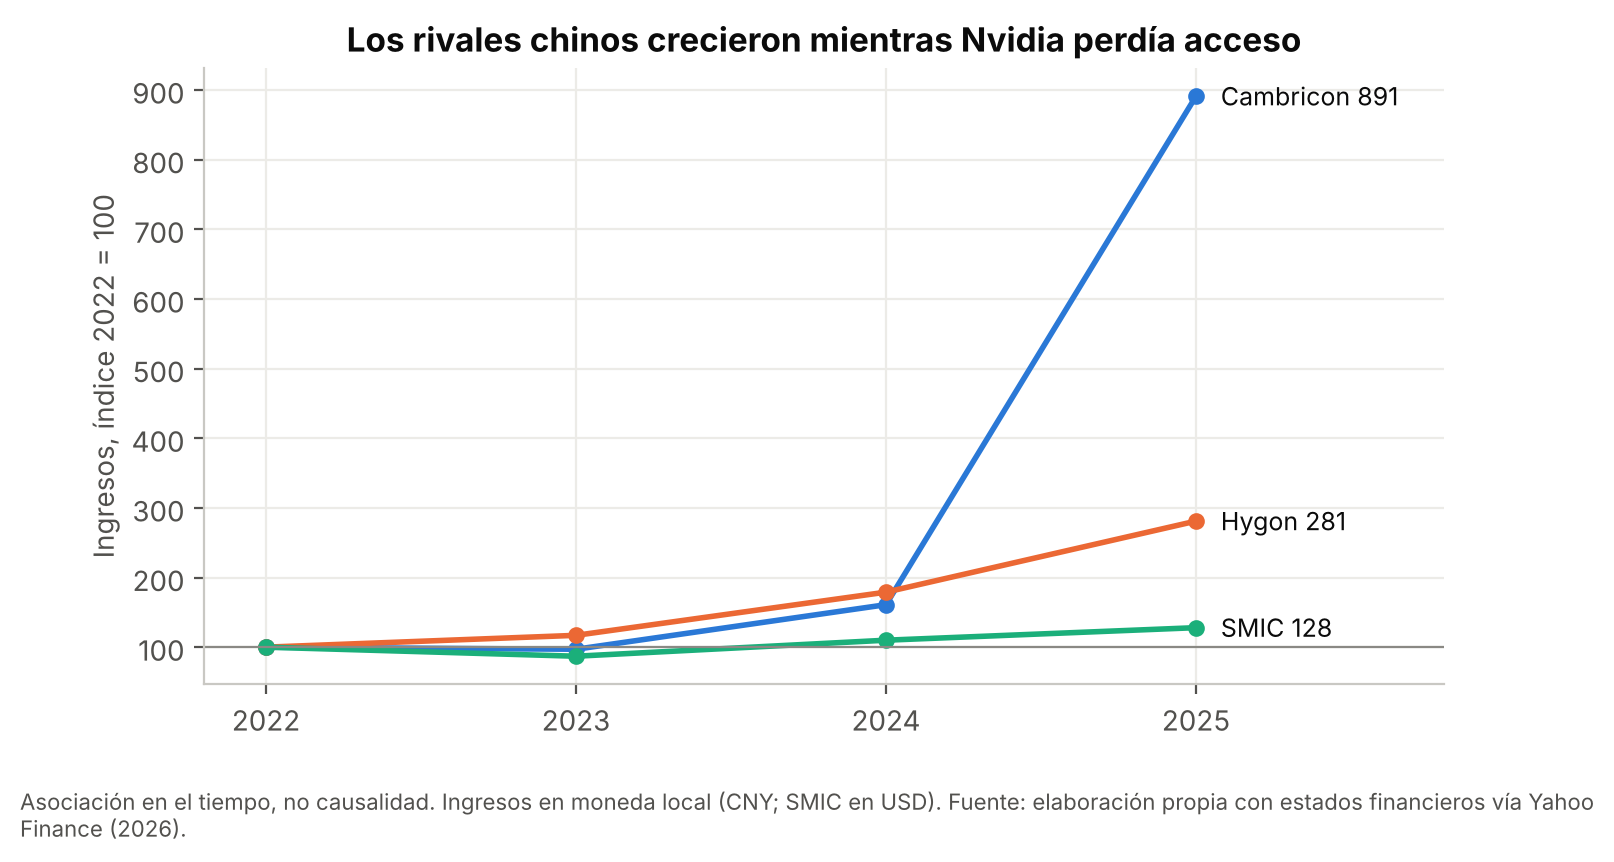

In [13]:
# Figura 4: crecimiento de rivales chinos (índice 2022 = 100)
fig, ax = plt.subplots(figsize=(8, 4))
for emp, c in [('Cambricon', S1), ('Hygon', S2), ('SMIC', S3)]:
    ax.plot(idx.index, idx[emp], color=c, marker='o', ms=5)
    ax.text(idx.index[-1]+0.08, idx[emp].iloc[-1], f'{emp} {idx[emp].iloc[-1]:.0f}', va='center', fontsize=9, color=TXT)
ax.axhline(100, color=GRIS, lw=0.8)
ax.set_xticks(idx.index); ax.set_xlim(2021.8, 2025.8); ax.set_ylabel('Ingresos, índice 2022 = 100')
ax.set_title('Los rivales chinos crecieron mientras Nvidia perdía acceso')
nota(fig, 'Asociación en el tiempo, no causalidad. Ingresos en moneda local (CNY; SMIC en USD). Fuente: elaboración propia con estados financieros vía Yahoo Finance (2026).')
fig.savefig(FIG/'fig4_rivales_chinos.png'); plt.show()

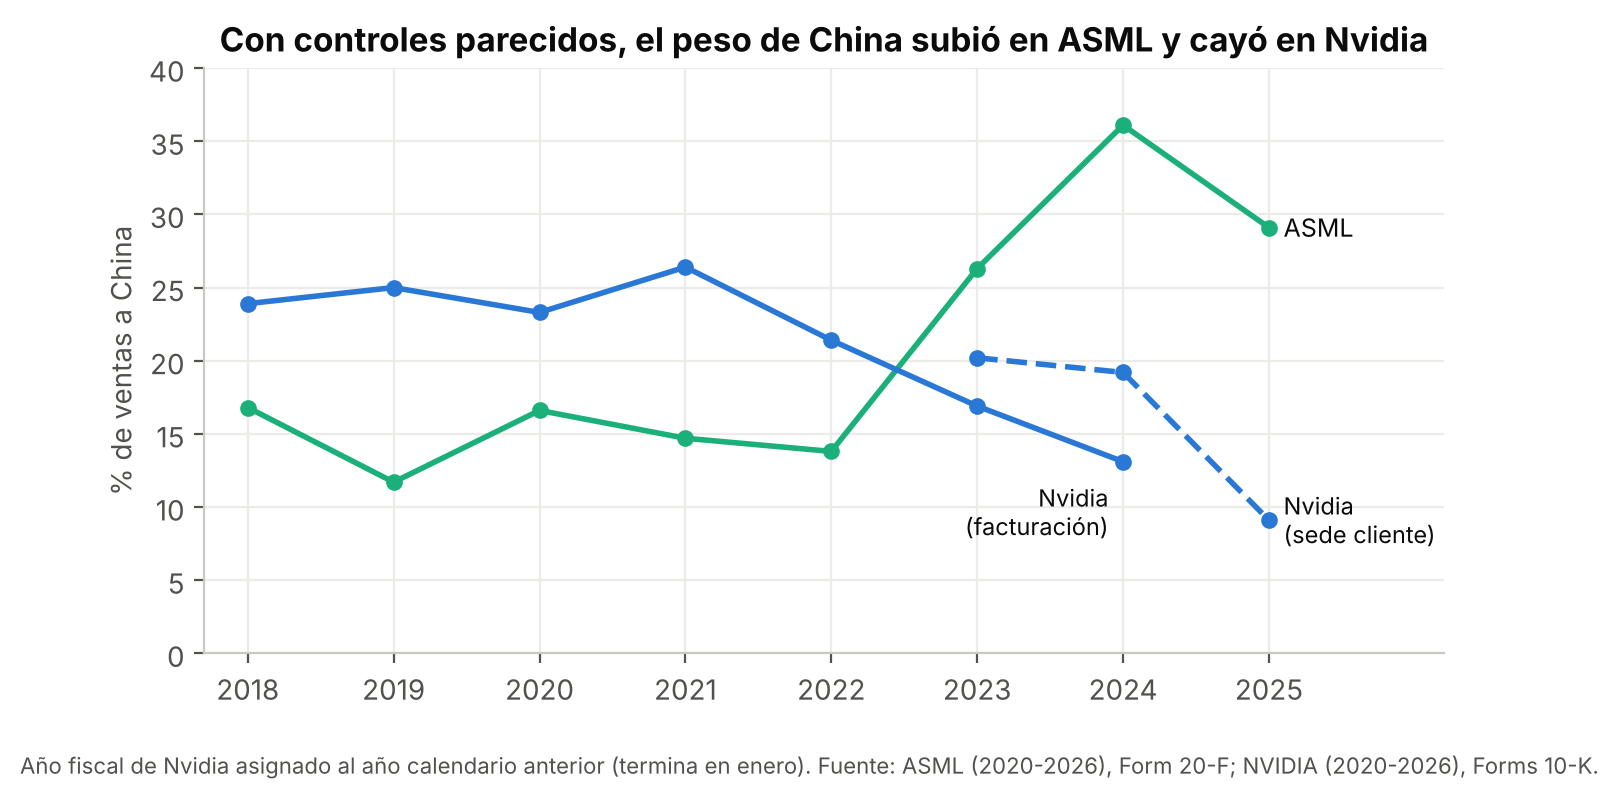

In [14]:
# Figura 5: recuadro ASML vs Nvidia (peso de China por año calendario aproximado)
fig, ax = plt.subplots(figsize=(8, 3.8))
c = cmp_[cmp_.anio >= 2018]
ax.plot(c.anio, c.ASML, color=S3, marker='o', ms=5)
ax.plot(c.anio, c.pct_china_facturacion, color=S1, marker='o', ms=5)
ax.plot(c.anio, c.pct_china_sede_cliente, color=S1, marker='o', ms=5, ls='--')
ax.text(2025.1, c.ASML.iloc[-1], 'ASML', va='center', fontsize=9, color=TXT)
ax.text(2023.9, c.pct_china_facturacion.dropna().iloc[-1]-1.5, 'Nvidia\n(facturación)', va='top', ha='right', fontsize=8.5, color=TXT)
ax.text(2025.1, c.pct_china_sede_cliente.dropna().iloc[-1], 'Nvidia\n(sede cliente)', va='center', fontsize=8.5, color=TXT)
ax.set_xlim(2017.7, 2026.2); ax.set_xticks(range(2018, 2026)); ax.set_ylim(0, 40); ax.set_ylabel('% de ventas a China')
ax.set_title('Con controles parecidos, el peso de China subió en ASML y cayó en Nvidia')
nota(fig, 'Año fiscal de Nvidia asignado al año calendario anterior (termina en enero). Fuente: ASML (2020-2026), Form 20-F; NVIDIA (2020-2026), Forms 10-K.')
fig.savefig(FIG/'fig5_asml_vs_nvidia.png'); plt.show()